# Práctica Tema 4.2 — Empaquetado y despliegue

**Maestría en Inteligencia Artificial · Visión Inteligente · Unidad IV · Actividad 4.2**
**Alumno:** David Díaz de la Cruz

---

## ¿Qué se hace en esta actividad?

En la 4.1 el pipeline funciona **en la máquina donde se construyó**. Ahora se empaqueta para que funcione
**en cualquier máquina**, incluso en un dispositivo pequeño, y se mide qué tan bien lo hace.

| Tarea pedida | Cómo se resuelve | Dónde |
|---|---|---|
| Estructura de entrega mínima (modelo, script, requirements, README) | Paquete `.zip` con manifiesto de huellas SHA-256 | `herramientas/empaquetar.py` → `dist/` |
| Dockerfile para contenedorización | Dos imágenes: **completa** (TensorFlow) y **edge** (TensorFlow Lite) | `Dockerfile`, `Dockerfile.edge` |
| Simular despliegue edge/contenedor con medición de rendimiento | Contenedores con límites de CPU y RAM + benchmark | `herramientas/benchmark_despliegue.py` |

### Conceptos clave

* **Contenedor:** un "paquete" que lleva el programa **junto con todo lo que necesita** (Python, librerías, modelo).
  Se ejecuta igual en cualquier equipo con Docker. Una analogía: el contenedor marítimo, que se mueve igual en un
  barco, un tren o un camión, sin importar qué lleve adentro.
* **Imagen vs. contenedor:** la *imagen* es la plantilla (se construye una vez con el `Dockerfile`); el *contenedor*
  es una ejecución de esa imagen.
* **Edge (borde):** ejecutar el modelo **cerca de donde se generan los datos** (una cámara, un gateway, una
  Raspberry Pi) en lugar de en un servidor central. Ventajas: menor latencia, funciona sin red, la imagen no viaja.
  Desventaja: poca CPU y poca memoria. Por eso el modelo y sus librerías deben ser **ligeros**.

## 0. Preparación

Este notebook usa Docker desde Python (`subprocess`). Requiere haber construido las dos imágenes
(ver `LEEME_DESPLIEGUE.md`) y haber ejecutado `python herramientas/benchmark_despliegue.py`.

In [1]:
import os, sys, json, subprocess, shutil
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt

FIG = Path("notebooks/figuras_4_2"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("benchmarks/resultados")
pd.set_option("display.width", 160)

def sh(comando):
    # Ejecuta un comando de terminal y devuelve su salida como texto
    return subprocess.run(comando, shell=True, capture_output=True, text=True).stdout.strip()

print(sh("docker --version"))
print(sh("docker images --format '{{.Repository}}:{{.Tag}}  {{.Size}}' | grep vision-figuras"))

Docker version 29.9.2, build a82e528
vision-figuras:1.0-completo  2.44GB
vision-figuras:1.0-edge  644MB


## 1. Estructura de entrega mínima

Un paquete de entrega profesional contiene **solo lo necesario para operar**: el modelo, el script, las dependencias
y las instrucciones. Los datos de entrenamiento, los notebooks y el historial de experimentos **no** viajan.
El script `herramientas/empaquetar.py` arma el `.zip` y agrega un `MANIFIESTO.json` con la huella SHA-256 de cada
archivo, para que quien lo reciba pueda verificar que nada se alteró en el camino.

In [2]:
print(sh(f"{sys.executable} herramientas/empaquetar.py"))
import zipfile
paquete = sorted(Path("dist").glob("*.zip"))[-1]
with zipfile.ZipFile(paquete) as z:
    nombres = [n.split("/", 1)[1] for n in z.namelist()]
grupos = pd.Series([n.split("/")[0] if "/" in n else n for n in nombres]).value_counts()
print("\nContenido del paquete (archivos por carpeta):")
print(grupos.to_string())

Paquete: dist/vision-figuras-v1.0.0.zip
Archivos: 62 | contenido: 5.9 MB | zip: 5.4 MB

Contenido del paquete (archivos por carpeta):
data                     32
src                      11
models                    7
config                    2
README.md                 1
LEEME_DESPLIEGUE.md       1
requirements.txt          1
requirements-api.txt      1
requirements-edge.txt     1
Dockerfile                1
Dockerfile.edge           1
docker-compose.yml        1
.dockerignore             1
docker                    1
MANIFIESTO.json           1


| Elemento mínimo pedido | En el paquete |
|---|---|
| Modelo | `models/` (`.keras`, cuatro variantes `.tflite`, `clases.txt`, `model_card.json`) |
| Script | `src/pipeline_operativo.py` (CLI), `src/api.py` (servicio), `src/benchmark.py` |
| Requirements | `requirements.txt` (completo), `requirements-edge.txt` (sin TensorFlow), `requirements-api.txt` |
| README | `README.md` (uso) y `LEEME_DESPLIEGUE.md` (Docker) |

## 2. Optimización del modelo para edge: TensorFlow Lite

El modelo `.keras` necesita TensorFlow, una librería de cientos de megabytes. Para un dispositivo pequeño se
convierte a **TensorFlow Lite** (`.tflite`), que se ejecuta con **LiteRT**, un runtime mucho más ligero.
`herramientas/convertir_tflite.py` hace la conversión en cuatro variantes:

| Variante | ¿Qué cambia? |
|---|---|
| `float32` | Solo el formato; los números son idénticos |
| `float16` | Pesos a media precisión |
| `int8_pesos` | Pesos en enteros de 8 bits; los cálculos y la salida siguen en decimal |
| `int8_completo` | Pesos **y** cálculos en 8 bits (lo que exigen aceleradores como Coral o una NPU) |

Antes de convertir se eliminan las capas de **aumento de datos** de la 3.3: solo sirven para entrenar.

,formato,precision,KB,exactitud_prueba,dif_max_prob_vs_keras,empates_prueba
modelo_figuras_v1.keras,keras,float32,3402.0,0.9944,NaN,NaN
modelo_figuras_v1_float32.tflite,tflite,float32,1121.0,0.9944,0.0,0
modelo_figuras_v1_float16.tflite,tflite,float16,565.0,0.9944,0.00088,0
modelo_figuras_v1_int8_pesos.tflite,tflite,int8_pesos,288.0,0.9944,0.00855,0
modelo_figuras_v1_int8_completo.tflite,tflite,int8_completo,290.0,1.0,0.16809,4


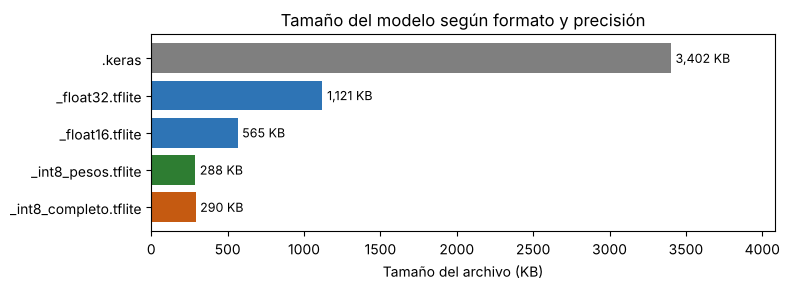

In [3]:
tarjeta = json.loads(Path("models/model_card.json").read_text(encoding="utf-8"))
art = pd.DataFrame(tarjeta["artefactos"]).T
art["KB"] = (art["bytes"].astype(float) / 1024).round(0)
tabla_mod = art[["formato", "precision", "KB", "exactitud_prueba", "dif_max_prob_vs_keras", "empates_prueba"]]
display(tabla_mod)

fig, ax = plt.subplots(figsize=(8, 3))
colores = ["#7f7f7f", "#2e74b5", "#2e74b5", "#2e7d32", "#c55a11"]
ax.barh([i.replace("modelo_figuras_v1", "") for i in art.index], art["KB"], color=colores)
for i, v in enumerate(art["KB"]):
    ax.text(v + 30, i, f"{v:,.0f} KB", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Tamaño del archivo (KB)"); ax.set_xlim(0, art["KB"].max() * 1.2)
ax.set_title("Tamaño del modelo según formato y precisión")
plt.tight_layout(); plt.savefig(FIG / "01_tamano_modelos.png", dpi=150); plt.show()

**Interpretación:**
* El `.keras` pesa 3.4 MB, pero el mismo modelo en `.tflite` float32 pesa 1.1 MB. El `.keras` también guarda el
  **estado del optimizador** Adam (dos valores extra por cada peso) para poder seguir entrenando; para predecir no
  hace falta.
* `float16` reduce el archivo a la mitad y la cuantización `int8` a una **cuarta parte**, sin perder exactitud
  (99.44 %). La diferencia de probabilidades con Keras crece con la compresión, pero no cambia ninguna decisión.
* **Hallazgo — empates en int8 completo:** su exactitud aparece como 100 %, pero es engañosa. Al guardar también
  la **salida** *softmax* en 8 bits, las probabilidades solo pueden tomar 256 valores, y en 4 imágenes dudosas dos clases
  quedan **empatadas** exactamente (0.5 y 0.5). El "acierto" depende de cómo se rompa el empate. Por eso el pipeline
  desempata siempre de la misma forma, gana la primera clase como en `argmax`, y la variante elegida para edge es
  `int8_pesos`: igual de pequeña, pero con salida decimal.

## 3. Contenedorización: dos Dockerfiles

Los dos Dockerfiles comparten la misma estructura. Lo que cambia es **qué se instala y qué modelo se copia**:

```dockerfile
ARG BASE_IMAGE=python:3.12-slim          # imagen oficial de Python, versión "slim" (mínima)
FROM ${BASE_IMAGE}
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 PIP_NO_CACHE_DIR=1 PIPELINE_CONFIG=config/config_edge.yaml
WORKDIR /app
RUN python3 -m venv /opt/venv            # entorno virtual dentro del contenedor
ENV PATH=/opt/venv/bin:$PATH
COPY requirements-edge.txt requirements-api.txt ./
RUN pip install -r requirements-edge.txt -r requirements-api.txt   # (1) dependencias: capa en caché
COPY config/ config/                                                 # (2) solo lo necesario
COPY models/clases.txt models/model_card.json models/*.tflite models/
COPY src/ src/
RUN useradd --create-home --uid 1000 app ...                         # (3) no ejecutar como root
USER app
EXPOSE 8000
HEALTHCHECK CMD python3 -c "...urlopen('http://localhost:8000/health')"   # (4) Docker vigila el servicio
ENTRYPOINT ["entrypoint.sh"]
CMD ["api"]
```

Decisiones de diseño:
1. **Dependencias antes que el código:** Docker reutiliza (caché) la capa de `pip install` mientras no cambien los
   `requirements`. Cambiar una línea de código reconstruye en segundos, no en minutos.
2. **`.dockerignore`:** datos, notebooks, entrenamiento y `.git` no entran a la imagen. Los datos se **montan** al
   ejecutar (`-v`), así la misma imagen sirve para cualquier conjunto de imágenes.
3. **Usuario sin privilegios:** si alguien explotara una falla del servicio, no tendría permisos de administrador.
4. **Un contenedor, tres usos** (`docker/entrypoint.sh`): sin argumentos levanta el **servicio web**; con
   `--modo ...` ejecuta el **pipeline**; con `benchmark` mide el **rendimiento**.

> **Nota del entorno de desarrollo:** en el equipo donde se construyó este proyecto, Docker Hub no está accesible.
> Las imágenes se construyeron con una base equivalente (Ubuntu 24.04 + Python 3.12) mediante
> `--build-arg BASE_IMAGE=...`. Con acceso normal a Docker Hub se usa `python:3.12-slim` sin cambiar nada.

### ¿Cuánto pesa cada imagen y por qué?

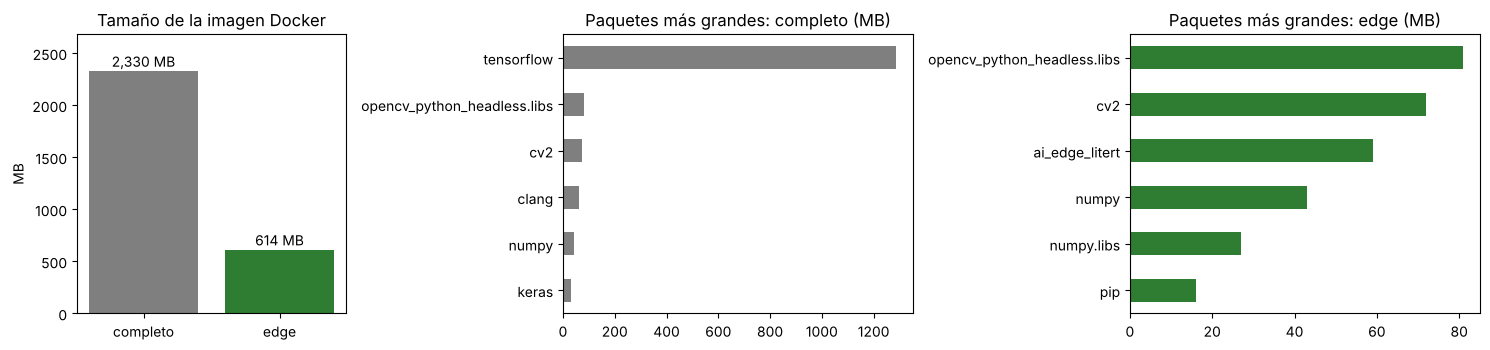

{'vision-figuras:1.0-completo': '2,330 MB', 'vision-figuras:1.0-edge': '614 MB'} -> la imagen edge es 3.8 veces más pequeña


In [4]:
def paquetes(imagen, n=6):
    # Tamaño (MB) de los paquetes de Python más grandes instalados en la imagen
    salida = sh(f"docker run --rm --entrypoint sh {imagen} -c "
                f"\"du -sm /opt/venv/lib/python3*/site-packages/* | sort -n | tail -{n}\"")
    filas = [l.split("\t") for l in salida.splitlines() if "\t" in l]
    return pd.Series({Path(r).name: int(mb) for mb, r in filas}).sort_values()

tamano = {i: int(sh(f"docker image inspect {i} --format '{{{{.Size}}}}'")) / 2**20
          for i in ["vision-figuras:1.0-completo", "vision-figuras:1.0-edge"]}
venv_c, venv_e = paquetes("vision-figuras:1.0-completo"), paquetes("vision-figuras:1.0-edge")

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
ejes[0].bar(["completo", "edge"], tamano.values(), color=["#7f7f7f", "#2e7d32"])
for i, v in enumerate(tamano.values()):
    ejes[0].text(i, v + 40, f"{v:,.0f} MB", ha="center")
ejes[0].set_title("Tamaño de la imagen Docker"); ejes[0].set_ylabel("MB"); ejes[0].set_ylim(0, max(tamano.values()) * 1.15)
venv_c.plot.barh(ax=ejes[1], color="#7f7f7f"); ejes[1].set_title("Paquetes más grandes: completo (MB)")
venv_e.plot.barh(ax=ejes[2], color="#2e7d32"); ejes[2].set_title("Paquetes más grandes: edge (MB)")
plt.tight_layout(); plt.savefig(FIG / "02_tamano_imagenes.png", dpi=150); plt.show()
print({k: f"{v:,.0f} MB" for k, v in tamano.items()}, f"-> la imagen edge es {tamano['vision-figuras:1.0-completo'] / tamano['vision-figuras:1.0-edge']:.1f} veces más pequeña")

**Interpretación:** la imagen completa pesa varias veces más que la edge, y casi todo es **TensorFlow**.
(En una primera versión también incluía scikit-learn y scipy, unos 150 MB que el contenedor no usa: solo los
necesitan las herramientas de preparación. Esta gráfica lo hizo evidente y se movieron a `requirements-notebook.txt`). La imagen
edge no lo necesita: el motor LiteRT ocupa unos 60 MB. Un detalle revelador: en la imagen edge el paquete más pesado
**ya no es el motor de IA sino OpenCV**, que se usa para leer y preprocesar imágenes. Si hiciera falta adelgazarla
más, el siguiente paso sería sustituir OpenCV por una librería más pequeña (por ejemplo Pillow) para esas tareas.

## 4. Evidencia de ejecución

Toda la salida de los comandos se guardó en `benchmarks/evidencia/`. Algunas muestras:

### 4.1 Construcción de las imágenes

In [5]:
for nombre in ["01_build_edge.log", "02_build_completo.log"]:
    lineas = Path("benchmarks/evidencia", nombre).read_text(encoding="utf-8").splitlines()
    pasos = [l for l in lineas if l.startswith("#") and ("[" in l and "/" in l.split("]")[0])]
    print(f"--- {nombre}: {len(lineas)} líneas")
    print("\n".join(dict.fromkeys(l.split(" ", 1)[1] for l in pasos if " " in l)))
    print("\n".join(lineas[-3:]), "\n")

--- 01_build_edge.log: 165 líneas
[ 1/10] FROM docker.io/base-local/python:3.12@sha256:7ddcbc33a65d4c7ef43ee17aa06d66be31efeec9bb44e8c3609d64617a9bd701
[ 2/10] WORKDIR /app
[ 3/10] RUN python3 -m venv /opt/venv
[ 4/10] COPY requirements-edge.txt requirements-api.txt ./
[ 5/10] RUN pip install -r requirements-edge.txt -r requirements-api.txt
[ 6/10] COPY config/ config/
[ 7/10] COPY models/clases.txt models/model_card.json models/*.tflite models/
[ 8/10] COPY src/ src/
[ 9/10] COPY docker/entrypoint.sh /usr/local/bin/entrypoint.sh
[10/10] RUN useradd --create-home --uid 1000 app && mkdir -p outputs data && chown -R app:app /app
real	0m41.204s
user	0m0.302s
sys	0m0.160s 

--- 02_build_completo.log: 248 líneas
[ 1/10] FROM docker.io/base-local/python:3.12@sha256:7ddcbc33a65d4c7ef43ee17aa06d66be31efeec9bb44e8c3609d64617a9bd701
[ 2/10] WORKDIR /app
[ 3/10] RUN python3 -m venv /opt/venv
[ 4/10] COPY requirements.txt requirements-api.txt ./
[ 5/10] RUN pip install -r requirements.txt -r requi

### 4.2 El pipeline dentro del contenedor (modo imagen)

In [6]:
print(Path("benchmarks/evidencia/arranque_edge_1.log").read_text(encoding="utf-8"))

$ docker run --rm -v /home/claude/maestria_modelo_vision_inteligente/data:/app/data:ro vision-figuras:1.0-edge --modo imagen --entrada data/ejemplos/nuevas/triangulo_1.png

20:47:33 | INFO    | === Ejecución 20261031-204733_imagen ===
20:47:33 | INFO    | Huella SHA-256 verificada (293c7a2f9518...)
20:47:33 | INFO    | Modelo cargado: modelo_figuras_v1_int8_pesos.tflite v1.0.0 (motor tflite) en 0.01 s
20:47:33 | INFO    | Dispositivo de ejecución: CPU (LiteRT, 1 hilos)
20:47:33 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
20:47:33 | INFO    | triangulo_1.png: triangulo (99.9%) [ok] en 0.5 ms
20:47:33 | INFO    | Resultados en: /app/outputs/20261031-204733_imagen

RESULTADO: triangulo  (99.93%)  [ok]
triangulo=99.93%  cuadrado=0.07%  circulo=0.00%
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.

[código de salida: 0] [duración: 0.60 s]



### 4.3 El servicio web dentro del contenedor

El contenedor se levanta en segundo plano, Docker consulta `/health` y se envía una imagen a `/predict`:

In [7]:
print(Path("benchmarks/evidencia/servicio_edge.log").read_text(encoding="utf-8"))

$ docker run -d -p 8101:8000 vision-figuras:1.0-edge

20:47:36 | INFO    | === Ejecución 20261031-204736_api ===
20:47:36 | INFO    | Huella SHA-256 verificada (293c7a2f9518...)
20:47:36 | INFO    | Modelo cargado: modelo_figuras_v1_int8_pesos.tflite v1.0.0 (motor tflite) en 0.01 s
20:47:36 | INFO    | Dispositivo de ejecución: CPU (LiteRT, 1 hilos)
20:47:36 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
INFO:     172.17.0.1:33274 - "GET /health HTTP/1.1" 200 OK
20:47:36 | INFO    | API /predict 'cuadrado_1.png': cuadrado (99.7%) en 0.5 ms
INFO:     172.17.0.1:33288 - "POST /predict HTTP/1.1" 200 OK
INFO:     Started server process [1]
INFO:     Waiting for application startup.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)

$ curl -F imagen=@cuadrado_1.png http://localhost:8101/predict
{"archivo":"cuadrado_1.png","clase":"c

### 4.4 Tiempo real dentro de un "dispositivo edge" simulado

El video de la 4.1 se procesa dentro del contenedor edge limitado a **un cuarto de núcleo y 128 MB de RAM**, primero
a 15 FPS (una cámara normal) y después a 200 FPS (más rápido de lo que puede procesar).

In [8]:
salida_docker = RAIZ / "outputs_docker"
salida_docker.mkdir(exist_ok=True); salida_docker.chmod(0o777)   # el contenedor escribe con su propio usuario
volumenes = f'-v "{RAIZ / "data"}:/app/data:ro" -v "{salida_docker}:/app/outputs"'
limites = "--cpus=0.25 --memory=128m --memory-swap=128m"
resultados_tr = {}
for fps in [15, 200]:
    cmd = (f"docker run --rm {limites} {volumenes} vision-figuras:1.0-edge --modo tiempo-real "
           f"--entrada data/video/figuras.mp4 --etiquetas data/video/figuras_etiquetas.csv --fps {fps}")
    log = sh(cmd + " 2>&1")
    Path(f"benchmarks/evidencia/tiempo_real_edge_{fps}fps.log").write_text(f"$ {cmd}\n\n{log}\n", encoding="utf-8")
    print(f"--- {fps} FPS\n" + "\n".join(l for l in log.splitlines() if "Cuadros" in l or "Dispositivo" in l))
    run = sorted(salida_docker.glob("*_tiempo-real"))[-1]
    resultados_tr[fps] = json.loads((run / "resumen.json").read_text(encoding="utf-8"))
display(pd.DataFrame({f"{k} FPS": {"recibidos": v["cuadros_recibidos"], "procesados": v["procesadas"],
                                    "descartados": v["cuadros_descartados"], "FPS efectivos": v["fps_efectivo"],
                                    "p95 (ms)": v["latencia_por_imagen"]["p95_ms"],
                                    "exactitud": v.get("exactitud")} for k, v in resultados_tr.items()}))

--- 15 FPS
20:48:06 | INFO    | Dispositivo de ejecución: CPU (LiteRT, 1 hilos)
20:48:36 | INFO    | Cuadros procesados 454 / descartados 2 | 15.0 FPS efectivos | p95 1.31 ms | exactitud 90.83% (suavizada 81.67%)


--- 200 FPS
20:48:38 | INFO    | Dispositivo de ejecución: CPU (LiteRT, 1 hilos)
20:48:40 | INFO    | Cuadros procesados 173 / descartados 283 | 75.6 FPS efectivos | p95 0.95 ms | exactitud 92.09% (suavizada 74.82%)


,15 FPS,200 FPS
recibidos,456.0000,456.0000
procesados,454.0000,173.0000
descartados,2.0000,283.0000
FPS efectivos,15.0000,75.6000
p95 (ms),1.3100,0.9500
exactitud,0.9083,0.9209


**Interpretación:**
* Con solo **un cuarto de núcleo**, el contenedor edge atiende la cámara de 15 FPS perdiendo apenas 2 de 456 cuadros
  (menos del 0.5 %, por las pausas con que Docker reparte la CPU limitada) y con la misma exactitud de la 4.1 (90.83 %).
* A 200 FPS procesa unos 75 cuadros por segundo y descarta el resto. Es la misma capacidad que tenía en la 4.1 el pipeline
  con Keras y **dos núcleos completos** (≈ 65 FPS), pero aquí con la octava parte de CPU.
* Con 200 FPS el cuello de botella **ya no es el modelo**: procesar un cuadro toma ≈ 1 ms (p95), pero leer cada
  cuadro del video, dibujar la anotación y escribir el video de salida toma mucho más. Optimizar el modelo dejó de ser lo
  prioritario; ahora lo serían la entrada y la salida.

## 5. Medición de rendimiento: host, contenedor completo y contenedor edge

`herramientas/benchmark_despliegue.py` ejecuta `src/benchmark.py` en 14 escenarios. Para simular equipos más modestos
se usan los límites de Docker: `--cpus` (fracción de núcleos) y `--memory` (RAM máxima; si el proceso la supera,
Docker lo detiene con el código 137, *OOM killed*). En cada escenario se mide:

* **Exactitud** con las 180 imágenes de prueba.
* **Latencia de punta a punta** con lote de 1: preprocesar + inferir una imagen (300 mediciones; p50 y p95).
* **Throughput** en lotes (imágenes por segundo).
* **Memoria**, separada en dos partes: la **propia** del proceso (datos, tensores; no se puede liberar) y la de
  **librerías** cargadas desde disco (el sistema puede liberarla y volver a leerla si falta memoria).

In [9]:
filas = []
for f in sorted(RES.glob("*.json")):
    if f.name == "arranque.json":
        continue
    d = json.loads(f.read_text(encoding="utf-8"))
    ok = "latencia_punta_a_punta" in d
    filas.append({
        "escenario": f.stem, "entorno": d.get("entorno"),
        "modelo": d.get("modelo", "modelo_figuras_v1.keras" if "completo" in f.stem else "modelo_figuras_v1_int8_pesos.tflite").replace("modelo_figuras_v1", ""),
        "límite CPU": d.get("cpus_docker") or "-", "límite RAM": d.get("memoria_docker") or "-",
        "estado": "ok" if ok else "detenido (OOM)",
        "exactitud": d.get("exactitud"), "p50_ms": d["latencia_punta_a_punta"]["p50_ms"] if ok else None,
        "p95_ms": d["latencia_punta_a_punta"]["p95_ms"] if ok else None,
        "img_s_lote32": d["throughput_img_s"].get("lote_32") if ok else None,
        "mem_propia_mb": d.get("memoria_anonima_mb"), "mem_librerias_mb": d.get("memoria_librerias_mb"),
        "carga_s": d.get("carga_s")})
bench = pd.DataFrame(filas)
orden = ["host_keras", "host_tflite_float32", "host_tflite_float16", "host_tflite_int8_pesos", "host_tflite_int8_completo",
         "docker_completo", "docker_completo_1cpu_1gb", "docker_completo_1cpu_512mb", "docker_completo_1cpu_256mb",
         "docker_completo_1cpu_128mb", "docker_edge", "docker_edge_0.5cpu_256mb", "docker_edge_0.25cpu_128mb", "docker_edge_0.25cpu_64mb"]
bench = bench.set_index("escenario").loc[orden].reset_index()
display(bench.style.format({"exactitud": "{:.2%}", "p50_ms": "{:.2f}", "p95_ms": "{:.2f}", "img_s_lote32": "{:,.0f}",
                            "mem_propia_mb": "{:.0f}", "mem_librerias_mb": "{:.0f}", "carga_s": "{:.2f}"}, na_rep="—")
        .map(lambda v: "background-color:#ffcdd2" if v == "detenido (OOM)" else "", subset=["estado"]).hide(axis="index"))

escenario,entorno,modelo,límite CPU,límite RAM,estado,exactitud,p50_ms,p95_ms,img_s_lote32,mem_propia_mb,mem_librerias_mb,carga_s
host_keras,host,.keras,-,-,ok,99.44%,12.64,17.71,"1,120",409,352,5.08
host_tflite_float32,host,_float32.tflite,-,-,ok,99.44%,0.48,0.61,"3,298",101,55,0.01
host_tflite_float16,host,_float16.tflite,-,-,ok,99.44%,0.35,0.50,"3,169",103,54,0.01
host_tflite_int8_pesos,host,_int8_pesos.tflite,-,-,ok,99.44%,0.15,0.26,"6,309",100,54,0.01
host_tflite_int8_completo,host,_int8_completo.tflite,-,-,ok,100.00%,0.30,0.40,"3,169",53,54,0.01
docker_completo,docker,.keras,-,-,ok,99.44%,12.29,18.69,990,312,338,3.62
docker_completo_1cpu_1gb,docker,.keras,1,1g,ok,99.44%,12.33,18.37,871,309,338,3.25
docker_completo_1cpu_512mb,docker,.keras,1,512m,ok,99.44%,10.97,16.82,917,309,338,2.50
docker_completo_1cpu_256mb,docker,.keras,1,256m,detenido (OOM),—,—,—,—,—,—,—
docker_completo_1cpu_128mb,docker,.keras,1,128m,detenido (OOM),—,—,—,—,—,—,—


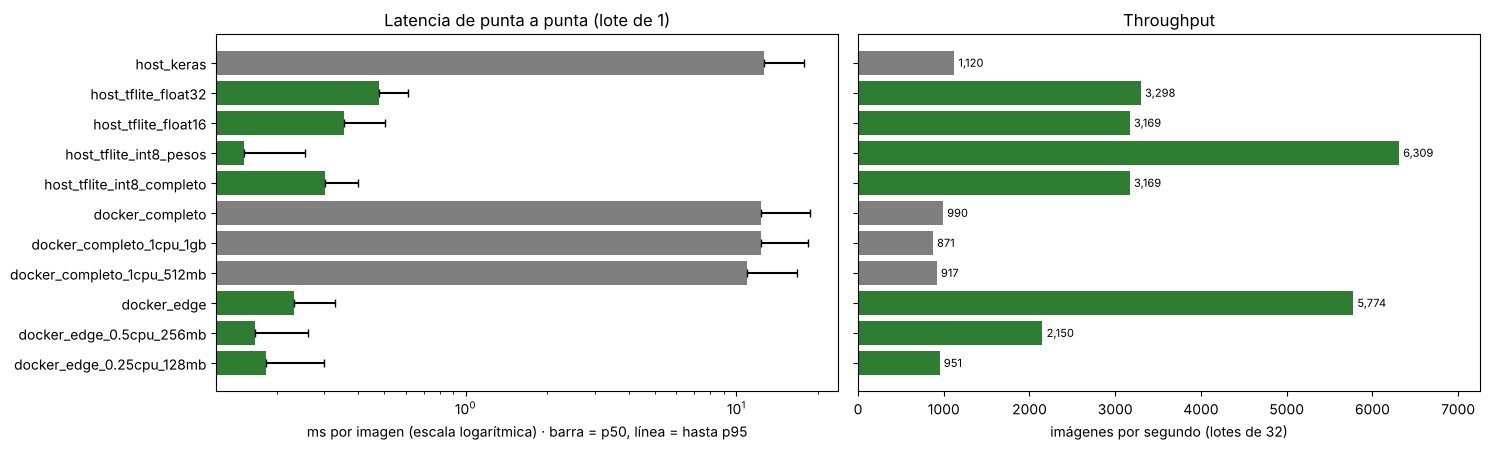

In [10]:
ok = bench[bench["estado"] == "ok"]
color = lambda e: "#7f7f7f" if ("keras" in e or "completo" in e and "int8" not in e) else "#2e7d32"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6))
y = np.arange(len(ok))
a1.barh(y, ok["p50_ms"], color=[color(e) for e in ok["escenario"]])
a1.errorbar(ok["p50_ms"], y, xerr=[np.zeros(len(ok)), ok["p95_ms"] - ok["p50_ms"]], fmt="none", ecolor="black", capsize=3)
a1.set_yticks(y, ok["escenario"]); a1.invert_yaxis(); a1.set_xscale("log")
a1.set_xlabel("ms por imagen (escala logarítmica) · barra = p50, línea = hasta p95")
a1.set_title("Latencia de punta a punta (lote de 1)")
a2.barh(y, ok["img_s_lote32"], color=[color(e) for e in ok["escenario"]])
a2.set_yticks(y, []); a2.invert_yaxis(); a2.set_xlabel("imágenes por segundo (lotes de 32)")
a2.set_xlim(0, ok["img_s_lote32"].max() * 1.15)
a2.set_title("Throughput")
for i, v in enumerate(ok["img_s_lote32"]):
    a2.text(v + 50, i, f"{v:,.0f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "03_latencia_throughput.png", dpi=150); plt.show()

**Latencia y throughput:**
* Pasar de **Keras a TensorFlow Lite** reduce la latencia de unos 12 ms a menos de 0.5 ms por imagen: **entre 25 y 80
  veces más rápido**, según la variante. La red es la misma; la diferencia está en el motor. Keras ejecuta cada capa como una operación
  independiente de Python y TensorFlow, con un costo fijo por llamada. LiteRT ejecuta el grafo ya compilado y
  optimizado para CPU (XNNPACK).
* **`int8_pesos` es la variante más rápida en CPU.** La `int8_completo`, a pesar de hacer todos los cálculos en 8 bits,
  es más lenta en este procesador: su ventaja aparece en aceleradores diseñados para enteros (NPU, Coral), no en
  una CPU de propósito general.
* **El contenedor no agrega costo:** el contenedor completo y el host con Keras dan prácticamente la misma latencia.
  Un contenedor no es una máquina virtual; el programa corre directo sobre el procesador.
* **Los límites de CPU sí se notan en el throughput:** baja de forma aproximadamente proporcional al límite. Con
  0.25 núcleos, el contenedor edge procesa entre el 15 y el 30 % de las imágenes por segundo que procesa sin límite
  (varía entre ejecuciones). La latencia de una sola imagen casi no cambia, porque una imagen
  tarda menos que el intervalo con el que Docker reparte la CPU (100 ms).

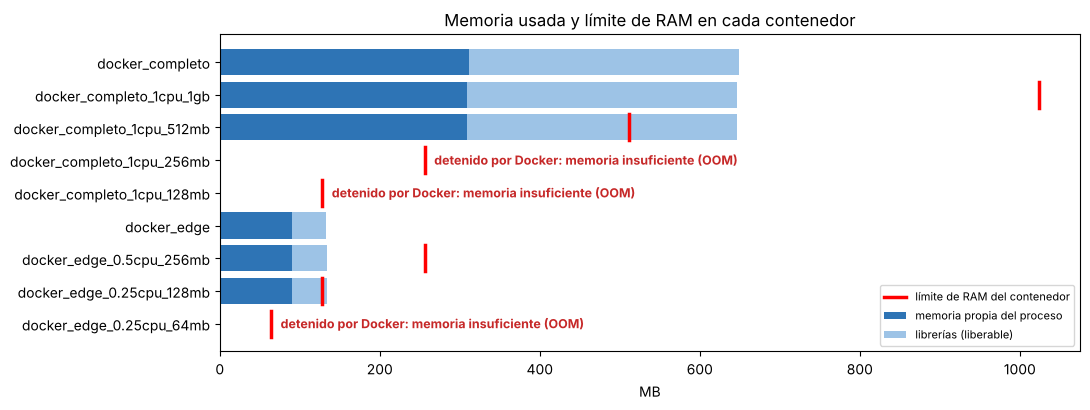

In [11]:
docker = bench[bench["entorno"] == "docker"].copy()
fig, ax = plt.subplots(figsize=(11, 4.2))
y = np.arange(len(docker))
ax.barh(y, docker["mem_propia_mb"].fillna(0), color="#2e74b5", label="memoria propia del proceso")
ax.barh(y, docker["mem_librerias_mb"].fillna(0), left=docker["mem_propia_mb"].fillna(0), color="#9dc3e6", label="librerías (liberable)")
for i, (_, f) in enumerate(docker.iterrows()):
    lim = f["límite RAM"]
    if lim != "-":
        mb = int(lim[:-1]) * (1024 if lim.endswith("g") else 1)
        ax.plot([mb, mb], [i - .4, i + .4], color="red", lw=2.5)
    if f["estado"] != "ok":
        ax.text(mb + 12, i, "detenido por Docker: memoria insuficiente (OOM)", va="center", color="#c62828", fontsize=9, fontweight="bold")
ax.plot([], [], color="red", lw=2.5, label="límite de RAM del contenedor")
ax.set_yticks(y, docker["escenario"]); ax.invert_yaxis(); ax.set_xlabel("MB"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Memoria usada y límite de RAM en cada contenedor")
plt.tight_layout(); plt.savefig(FIG / "04_memoria_limites.png", dpi=150); plt.show()

**Memoria — el factor que decide dónde se puede desplegar:**
* El contenedor **completo** necesita unos 310 MB propios más unos 340 MB de librerías. Funciona con 512 MB de RAM,
  porque el sistema puede liberar parte de las librerías, pero con **256 MB Docker lo detiene**: no cabe en un
  dispositivo pequeño.
* El contenedor **edge** usa unos 90 MB propios y 43 MB de librerías. Funciona con **128 MB** y solo falla con 64 MB.
* En resumen, el despliegue edge necesita **cuatro veces menos memoria** con la misma exactitud.

## 6. Arranque en frío

En edge y en la nube los contenedores se reinician con frecuencia (actualizaciones, cortes de energía, escalado). Se
mide cuánto tarda **desde `docker run` hasta tener la primera predicción** (modo imagen, mediana de 3) y cuánto tarda
el **servicio web en responder `/health`**.

,imagen,tamano_imagen_mb,docker_run_hasta_prediccion_s,servicio_hasta_health_s
completo,vision-figuras:1.0-completo,2330,4.39,3.42
edge,vision-figuras:1.0-edge,614,0.6,1.0


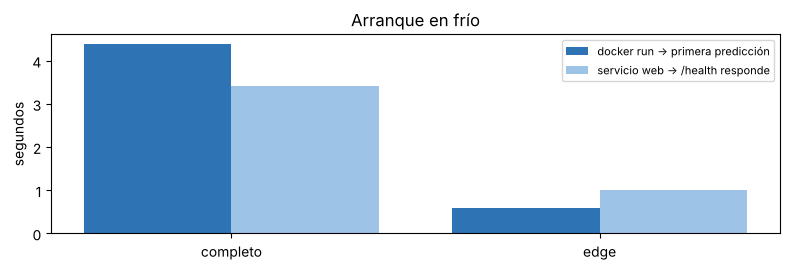

In [12]:
arr = pd.DataFrame(json.loads((RES / "arranque.json").read_text(encoding="utf-8"))).T
display(arr)
fig, ax = plt.subplots(figsize=(8, 2.8))
x = np.arange(2)
ax.bar(x - .2, arr["docker_run_hasta_prediccion_s"].astype(float), .4, label="docker run → primera predicción", color="#2e74b5")
ax.bar(x + .2, arr["servicio_hasta_health_s"].astype(float), .4, label="servicio web → /health responde", color="#9dc3e6")
ax.set_xticks(x, arr.index); ax.set_ylabel("segundos"); ax.legend(fontsize=8); ax.set_title("Arranque en frío")
plt.tight_layout(); plt.savefig(FIG / "05_arranque.png", dpi=150); plt.show()

**Interpretación:** el contenedor edge está listo en **menos de un segundo**; el completo tarda más de 4 s, casi todo en
**importar TensorFlow**. Cargar el modelo `.tflite` toma unos 10 ms. Para un dispositivo que se reinicia, o un servicio
que escala agregando copias según la demanda, esa diferencia es importante.

## 7. Conclusiones y recomendación de despliegue

| Criterio | Completo (Keras + TensorFlow) | Edge (TFLite int8 + LiteRT) |
|---|---|---|
| Exactitud | 99.44 % | 99.44 % |
| Tamaño del modelo | 3.4 MB | 0.29 MB |
| Tamaño de la imagen Docker | ≈ 2.3 GB | ≈ 0.6 GB |
| Latencia por imagen (p50) | ≈ 12 ms | ≈ 0.2 ms |
| RAM mínima | 512 MB | 128 MB |
| Arranque en frío | ≈ 4.4 s | ≈ 0.6 s |

1. **La optimización del modelo importa más que el hardware.** Con la misma red y la misma exactitud, cambiar de formato
   y de motor (TFLite con pesos int8) reduce 12 veces el modelo, 4 veces la imagen y la memoria, y hace la inferencia
   decenas de veces más rápida.
2. **El contenedor resuelve la reproducibilidad sin costo de rendimiento**, y los límites de Docker permiten probar antes
   de comprar hardware: el modelo edge funciona con un cuarto de núcleo y 128 MB.
3. **Medir evita conclusiones equivocadas:** la cuantización completa no fue la más rápida en CPU, su 100 % de
   exactitud venía de empates, y en la imagen edge el componente más pesado es OpenCV, no el motor de IA.

**Recomendación:** desplegar la imagen **edge** en dispositivos cercanos a la cámara (gateways, equipos industriales)
y reservar la imagen **completa** para reentrenar, depurar o servir en un servidor con recursos de sobra.

**Siguiente paso (Actividad 4.3):** integrar todo en la versión 1.0, con el manual de instalación y operación y el
video-demo del sistema funcionando.